# Video Games Sales 

In [2]:
# Importación de Librerias
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.model_selection import train_test_split

---

In [3]:
df = pd.read_csv('../data/raw/vgsales.csv')
df.head()

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.0,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.0,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.0,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.0,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.0,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  str    
 2   Platform      16598 non-null  str    
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  str    
 5   Publisher     16540 non-null  str    
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), str(4)
memory usage: 2.1 MB


In [5]:
df.isnull().sum()

Rank              0
Name              0
Platform          0
Year            271
Genre             0
Publisher        58
NA_Sales          0
EU_Sales          0
JP_Sales          0
Other_Sales       0
Global_Sales      0
dtype: int64

In [6]:
df_clean = df.dropna().copy()
df_clean.info()
display(df_clean.isnull().sum())

<class 'pandas.DataFrame'>
Index: 16291 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16291 non-null  int64  
 1   Name          16291 non-null  str    
 2   Platform      16291 non-null  str    
 3   Year          16291 non-null  float64
 4   Genre         16291 non-null  str    
 5   Publisher     16291 non-null  str    
 6   NA_Sales      16291 non-null  float64
 7   EU_Sales      16291 non-null  float64
 8   JP_Sales      16291 non-null  float64
 9   Other_Sales   16291 non-null  float64
 10  Global_Sales  16291 non-null  float64
dtypes: float64(6), int64(1), str(4)
memory usage: 2.2 MB


Rank            0
Name            0
Platform        0
Year            0
Genre           0
Publisher       0
NA_Sales        0
EU_Sales        0
JP_Sales        0
Other_Sales     0
Global_Sales    0
dtype: int64

In [7]:
df_clean['Year'] = df_clean['Year'].astype(int)

In [8]:
df_clean.info()
display(df_clean.head())


<class 'pandas.DataFrame'>
Index: 16291 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16291 non-null  int64  
 1   Name          16291 non-null  str    
 2   Platform      16291 non-null  str    
 3   Year          16291 non-null  int64  
 4   Genre         16291 non-null  str    
 5   Publisher     16291 non-null  str    
 6   NA_Sales      16291 non-null  float64
 7   EU_Sales      16291 non-null  float64
 8   JP_Sales      16291 non-null  float64
 9   Other_Sales   16291 non-null  float64
 10  Global_Sales  16291 non-null  float64
dtypes: float64(5), int64(2), str(4)
memory usage: 2.2 MB


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [9]:
print(df_clean['Year'].min())
print(df_clean['Year'].max())

1980
2020


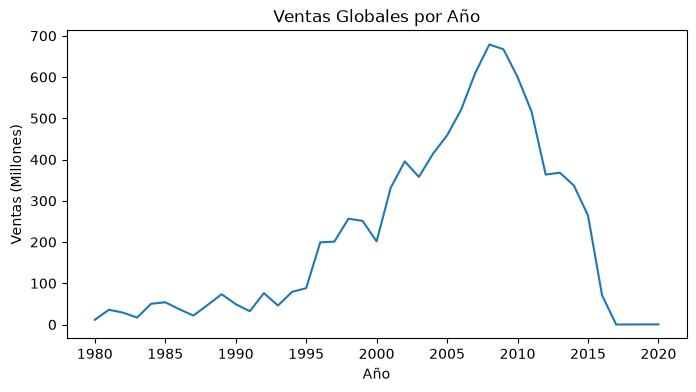

In [10]:
ventas_por_anio = df_clean.groupby('Year')['Global_Sales'].sum()

ventas_por_anio.plot(kind='line', figsize=(8, 4), title='Ventas Globales por Año')
plt.xlabel('Año')
plt.ylabel('Ventas (Millones)')
plt.show()

Las ventas aumentaron a una tendencia alcista a partir de los años noventa hasta alcanzar su punto más alto en 2008. Después comenzaron a disminuir. Esto muestra un cambio en el mercado de los juegos considerable según el año, esto puede deberse a cambios en las consolas, habitos de los jugadores, tendencias economicas, etc... Los datos no permiten relacionar esto a una causa.

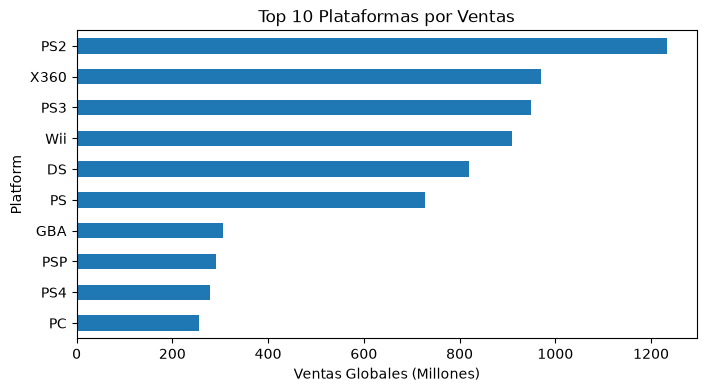

In [11]:
top_plataformas = df_clean.groupby('Platform')['Global_Sales'].sum().sort_values().tail(10)

top_plataformas.plot(kind='barh', figsize=(8, 4), title='Top 10 Plataformas por Ventas')
plt.xlabel('Ventas Globales (Millones)')
plt.show()

La PS2 lidera las ventas acumuladas, lo que muestra el éxito que tuvo durante su generación. Xbox 360, PS3 y Wii también destacan. Esto sugiere que la plataforma puede ser una característica relevante al analizar el éxito de un videojuego, aunque vender más en una plataforma no significa que todos sus juegos tengan mejores resultados.

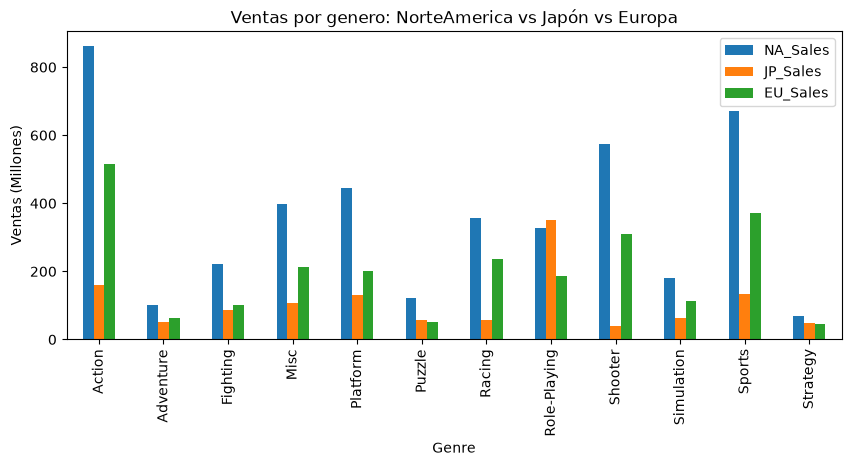

In [12]:
ventas_genero = df_clean.groupby('Genre')[['NA_Sales', 'JP_Sales', 'EU_Sales']].sum()

ventas_genero.plot(kind='bar', figsize=(10, 4), title='Ventas por genero: NorteAmerica vs Japón vs Europa')
plt.ylabel('Ventas (Millones)')
plt.show()

Las preferencias cambian según la región. Acción y deportes tienen una presencia marcada en NA, mientras que los juegos de rol destacan especialmente en Japón. Esto nos sugiere que el mercado no tiene preferencias globales y que la región es importante en el comportamiento comercial de los juegos

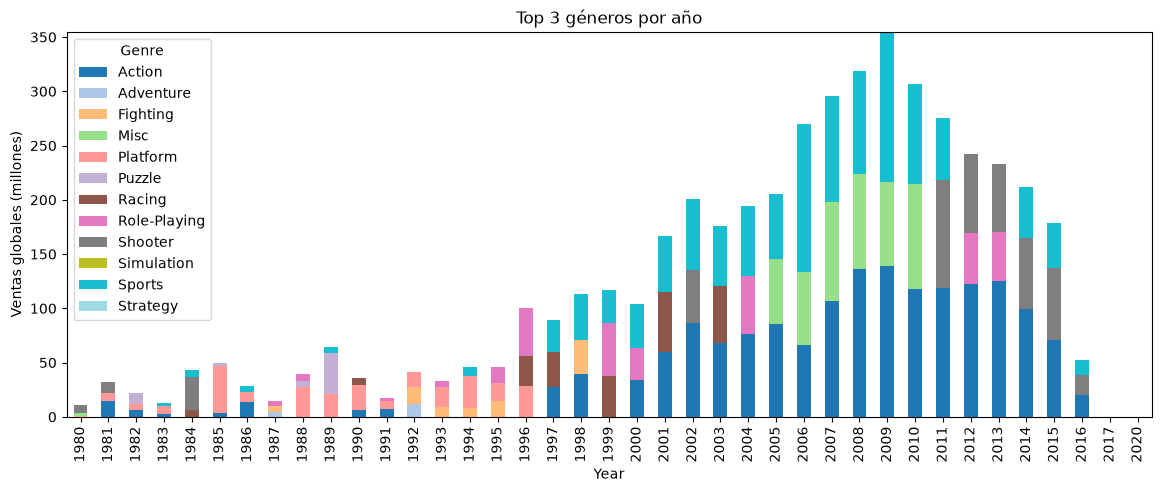

In [13]:
top3 = df_clean.pivot_table(
    index='Year', columns='Genre',
    values='Global_Sales', aggfunc='sum'
)

top3.where(top3.rank(axis=1, ascending=False) <= 3, 0).plot(
    kind='bar', stacked=True, figsize=(14, 5),
    title='Top 3 géneros por año',
    colormap='tab20'
)

plt.ylabel('Ventas globales (millones)')
plt.show()

Durante los primeros años existe una mayor variedad de géneros entre los más vendidos, mientras que a partir de los años 2000 destacan especialmente acción, deportes y disparos. Esto podría reflejar cambios en las preferencias de los consumidores y en la oferta de videojuegos.

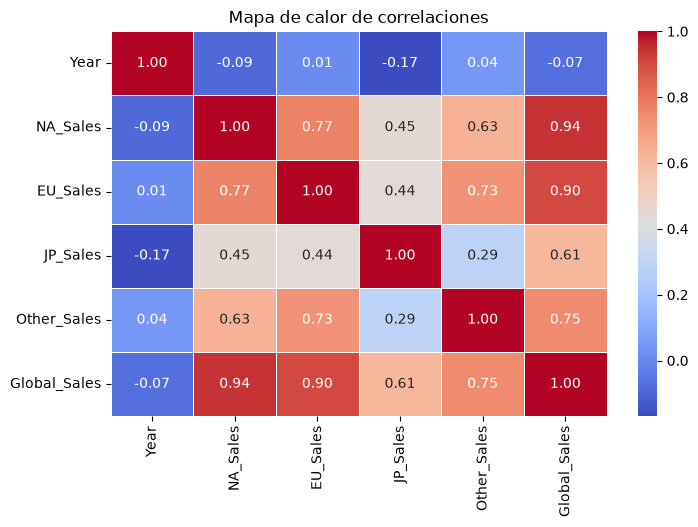

In [19]:
plt.figure(figsize=(8, 5))

correlacion = df_clean[
    ['Year', 'NA_Sales', 'EU_Sales', 'JP_Sales',
     'Other_Sales', 'Global_Sales']
].corr()

sns.heatmap(correlacion, annot=True, cmap='coolwarm',
            fmt='.2f', linewidths=0.5)

plt.title('Mapa de calor de correlaciones')
plt.show()

Las ventas de NA y Europa muestran patrones similares, lo que sugiere que los videojuegos populares en una región suelen tener buenos resultados en la otra. 

En cambio, Japón presenta un comportamiento menos relacionado con estos mercados, reflejando diferencias en las preferencias regionales. También observamos que el año de lanzamiento no esta correlacionado con el éxito, ya que existen grandes diferencias de ventas entre juegos de un mismo periodo.

---

---

In [14]:
df_clean['Exito'] = (df_clean['Global_Sales'] >= 1.0).astype(int) # Si vendio más de 1M, exito

df_clean

,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales,Exito
0,1,Wii Sports,Wii,2006,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74,1
1,2,Super Mario Bros.,NES,1985,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24,1
2,3,Mario Kart Wii,Wii,2008,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82,1
3,4,Wii Sports Resort,Wii,2009,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00,1
4,5,Pokemon Red/Pokemon Blue,GB,1996,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37,1
...,...,...,...,...,...,...,...,...,...,...,...,...
16593,16596,Woody Woodpecker in Crazy Castle 5,GBA,2002,Platform,Kemco,0.01,0.00,0.00,0.00,0.01,0
16594,16597,Men in Black II: Alien Escape,GC,2003,Shooter,Infogrames,0.01,0.00,0.00,0.00,0.01,0
16595,16598,SCORE International Baja 1000: The Official Game,PS2,2008,Racing,Activision,0.00,0.00,0.00,0.00,0.01,0
16596,16599,Know How 2,DS,2010,Puzzle,7G//AMES,0.00,0.01,0.00,0.00,0.01,0


In [15]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

X = df_clean[['Platform', 'Year', 'Genre', 'Publisher']]
y = df_clean['Exito']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


X_train = pd.get_dummies(X_train) 
X_test = pd.get_dummies(X_test)


X_test = X_test.reindex(columns=X_train.columns, fill_value=0) # Si falta alguna columna, la agrega rellena de puro 0

,precision,recall,f1-score
No exitoso,0.887874,0.990165,0.936234
Exitoso,0.666667,0.135922,0.225806


Accuracy: 0.88


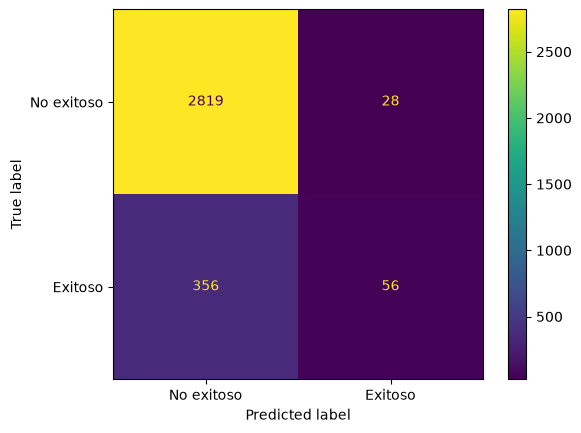

In [16]:
modelo = DecisionTreeClassifier(max_depth=5, random_state=42)
modelo.fit(X_train, y_train)


predicciones = modelo.predict(X_test)



reporte = classification_report(
    y_test, predicciones,
    target_names=['No exitoso', 'Exitoso'],
    output_dict=True
)

display(pd.DataFrame(reporte).T.loc[
    ['No exitoso', 'Exitoso'],
    ['precision', 'recall', 'f1-score']
])

print(f"Accuracy: {reporte['accuracy']:.2f}")



ConfusionMatrixDisplay.from_predictions(
    y_test, predicciones,
    display_labels=['No exitoso', 'Exitoso']
)
plt.show()

,precision,recall,f1-score
No exitoso,0.914731,0.885494,0.899875
Exitoso,0.351889,0.429612,0.386885


Accuracy: 0.83


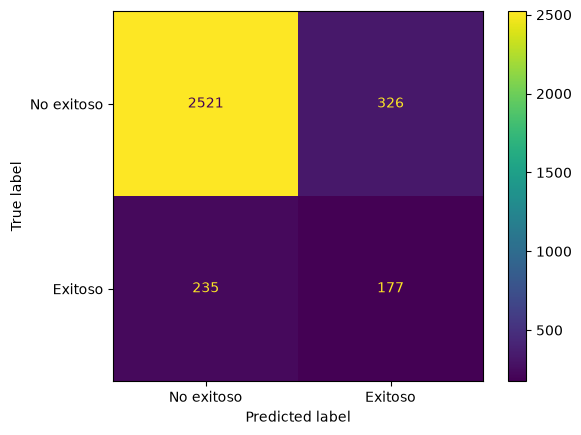

In [17]:
# Segundo modelo: árbol de decisión con clases balanceadas

modelo_balanceado = DecisionTreeClassifier(
    max_depth=5,
    random_state=42,
    class_weight='balanced'
)

modelo_balanceado.fit(X_train, y_train)

predicciones_balanceadas = modelo_balanceado.predict(X_test)



reporte = classification_report(
    y_test, predicciones_balanceadas,
    target_names=['No exitoso', 'Exitoso'],
    output_dict=True
)

display(pd.DataFrame(reporte).T.loc[
    ['No exitoso', 'Exitoso'],
    ['precision', 'recall', 'f1-score']
])

print(f"Accuracy: {reporte['accuracy']:.2f}")



ConfusionMatrixDisplay.from_predictions(
    y_test, predicciones_balanceadas,
    display_labels=['No exitoso', 'Exitoso']
)

plt.show()

Modelo 1: Árbol de decisión original


- Accuracy (0.88): Clasificó correctamente el 88% de los videojuegos.

- Precision: Acertó el 89% de sus predicciones de videojuegos no exitosos y el 67% de los exitosos.

- Recall: Identificó el 99% de los no exitosos, pero solamente el 14% de los exitosos.

- F1-score: Fue de 0.94 para no exitosos y 0.23 para exitosos, mostrando dificultades para detectar esta última clase.

Modelo 2: Árbol de decisión balanceado

- Accuracy (0.83): Clasificó correctamente el 83% de los videojuegos.

- Precision: Acertó el 91% de sus predicciones de no exitosos y el 35% de los exitosos.

- Recall: Identificó el 89% de los no exitosos y el 43% de los exitosos.

- F1-score: Fue de 0.90 para no exitosos y 0.39 para exitosos, mejorando la detección de la clase que nos interesa.

Conclusión: El primer modelo obtuvo mayor exactitud, pero el segundo identifico más videojuegos exitosos. Pero cometió más errores al hacerlo, resultó este segundo modelo ser el más adecuado para el objetivo de detectar éxitos comerciales... aunque aún dejando bastante margen de error.

,precision,recall,f1-score
No exitoso,0.942883,0.730594,0.823273
Exitoso,0.271605,0.694175,0.390444


Accuracy: 0.73


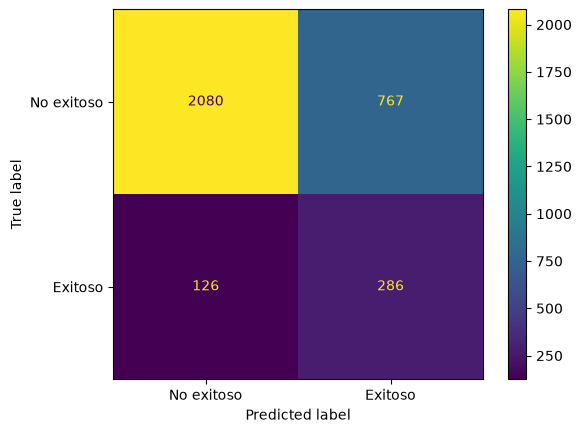

In [18]:
from sklearn.ensemble import RandomForestClassifier

modelo_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42,
    class_weight='balanced'
)

modelo_rf.fit(X_train, y_train)

predicciones_rf = modelo_rf.predict(X_test)

reporte = classification_report(
    y_test, predicciones_rf,
    target_names=['No exitoso', 'Exitoso'],
    output_dict=True
)

display(pd.DataFrame(reporte).T.loc[
    ['No exitoso', 'Exitoso'],
    ['precision', 'recall', 'f1-score']
])

print(f"Accuracy: {reporte['accuracy']:.2f}")

ConfusionMatrixDisplay.from_predictions(
    y_test, predicciones_rf,
    display_labels=['No exitoso', 'Exitoso']
)

plt.show()

El modelo RForest obtuvo un recall del 69% en la clase de juegos exitosos, siendo el mejor resultado entre los tres modelos para identificar esta categoría. Sin embargo, su precisión fue de apenas 27%, lo que nos indica que también clasificó incorrectamente muchos videojuegos como exitosos. Aunque mejoró ligeramente el F1-score respecto al árbol balanceado, su accuracy disminuyó a 73%.

Este modelo detecta más juegos exitosos, pero a costa de generar más FP.